# Lecture 18, Bias correction

> Removing the systematic errors of a climate model before it is used in hydrology

A climate model run does not match the rain gauges. It drizzles on too many days, its heavy rain is too weak, and its temperature is off. If we feed such rain into a flood model, the flood will be wrong before the hydrology even starts. Bias correction repairs these errors using the gauge record. The lecture follows Chapter 4 of Lee & Singh (2019) section by section (4.1 to 4.5), with the section numbers in the headings.

By the end of this lecture you should be able to:

- say what $y_{obs}$, $x_{m,base}$ and $x_{m,fut}$ stand for,
- remove surplus drizzle from model rainfall with a wet-day threshold,
- apply the empirical adjustment (delta method) and quantile mapping,
- apply quantile delta mapping and say why it keeps the model's projected change,
- solve a small quantile-mapping problem by hand and compare it with the code and the spreadsheet.

The workbook `data/downscaling/lec18/lec18_worked_examples.xlsx` repeats the hand examples (sheet `Occ_QM`), the delta method (`Delta`) and QDM (`QDM`). All data are **synthetic**.

In [1]:
# Google Colab setup: install the packages this notebook uses.
# Runs only on Colab; skipped in Binder or a local Jupyter install.
import sys
if "google.colab" in sys.modules:
    %pip install -q numpy pandas scipy matplotlib

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})

## Statistics words you need

- **Mean**: the average. The mean of 2, 4, 6 is 4.
- **Standard deviation**: the typical distance of the values from their mean. For 2, 4, 6 it is 2, so 'spread' means the standard deviation.
- **Rank**: the place of a value when the values are sorted from smallest. In 1.0, 3.5, 5.5, 8.0, 11.0 the value 5.5 has rank 3.
- **Empirical CDF (cumulative distribution function)**: the share of the data at or below a value, estimated as rank/(number of values + 1). For 5.5 it is $3/6 = 0.5$: about half of the days are at or below 5.5 mm. We write it $\hat F$.
- **Quantile and percentile**: the value that a given share of the data falls below. The 0.5 quantile (50th percentile) of the five numbers above is 5.5; the 0.8 quantile (80th percentile) is about 8 to 11. $F^{-1}$ turns a share back into a value.
- **Wet-day threshold**: the smallest amount of rain that still counts as a rainy day, for example 0.9 mm in the hand example.

## Notation

The symbols follow Lee & Singh (2019), Chapter 4. Rule for the code: drop the hat and the commas, write Greek letters out, and add `_hat` for an adjusted quantity. A sample sorted in increasing order is $x_{(i)}$.

| Book symbol | Meaning | Code and spreadsheet |
|:--|:--|:--|
| $y_{obs}$ | observed series | `y_obs` |
| $x_{m,base}$ | model series, base (historical) period | `x_m_base` |
| $x_{m,fut}$ | model series, future period (the series to correct) | `x_m_fut` |
| $\hat y_{m,fut}$ | bias-corrected future model series | `y_hat_m_fut` |
| $\mu_{m,fut}$, $\sigma_{m,fut}$ | mean and standard deviation of $x_{m,fut}$ (likewise $\mu_{obs}$, $\sigma_{obs}$, $\mu_{m,base}$, $\sigma_{m,base}$) | `mu_m_fut`, `sigma_m_fut`, ... |
| $z_{m,fut}$ | standardised future value (Eq. 4.1) | `z_m_fut` |
| $\hat\mu_{m,fut}$, $\hat\sigma_{m,fut}$ | adjusted mean and standard deviation (Eqs. 4.3 to 4.5) | `mu_hat`, `sigma_hat` |
| $F_o$, $F_{m,base}$, $F_{m,fut}$ | CDFs of the observed, model-base and model-future series | `F_o`, `F_m_base`, `F_m_fut` |
| $\hat F(x_{(i)}) = i/(N+1)$ | empirical CDF (Eq. 4.8) | `i / (N + 1)` |
| $\tau_{m,fut}$ | probability of $x_{m,fut}$ in its own CDF, $F_{m,fut}(x_{m,fut})$ (Eq. 4.9) | `tau_m_fut` |
| $\Delta_{m,fut}$, $\hat y_{o,fut}$ | QDM relative change and observed quantile (Eqs. 4.10, 4.11) | `Delta_m_fut`, `y_hat_o_fut` |
| $\alpha$, $\beta$ | gamma shape and scale, $\beta = \sigma^2/\mu$, $\alpha = \mu/\beta$; the exponential parameter $\alpha$ is the mean | `a_o`, `beta_o`, `alpha_o` ... |
| $N$, $n_1$ | number of values; number of values above zero | `N`, `n1` |

## 4.1 Why bias correction?

Think of a rain gauge that always reads a bit low. You would compare it with a good one and fix it. A climate model is the same: its outputs differ systematically from the gauge's (convection schemes, unresolved orography, internal variability). The **delta method** fixes mean and variance; **quantile mapping** (QM) fixes all quantiles, from light to heavy rain.

A model gives output for two periods. The **base** period is the one that matches the observations, and the **future** period is the one with climate forcings. The target to correct is the future model value $x_{m,fut}$. Using the observations $y_{obs}$ and the base model value $x_{m,base}$, it is transformed (mapped) into the observation domain, and the result is $\hat y_{m,fut}$. The base period and the observed period are normally, but not necessarily, the same years. The method assumes that the model's error stays the same in the future.

*What this means for hydrology:* a catchment model fed with uncorrected rain gives the wrong runoff.

## 4.2 Occurrence adjustment for precipitation data

Models produce rain on more days than the gauge shows. To remove this difference, some fraction of the model's rain values must be set to zero. This is done by comparing the number of observed and model values greater than zero. Plain idea: if the gauge was wet on 8 days out of 12, only the 8 heaviest model days should stay wet.

- **Same number of values:** sort observed and model values in descending order and set the model values smaller than the $n_1$th largest to zero, where $n_1$ is the number of observed values above zero.
- **Different numbers of values:** estimate the occurrence probability of the observations, $n_1/N$ (with $N$ the number of values), and use the $100(1 - n_1/N)$th percentile of the model values as the threshold (the model value that a share $1 - n_1/N$ of the model days fall below). Model values below it become zero.

A small amount of model rain is thereby treated as no rain, as in a real gauge.

*What this means for hydrology:* the right number of dry days matters for soil moisture, droughts and baseflow.

### Worked example (by hand): occurrence adjustment

**Problem.** Daily rain (mm) on 12 days: observed $y_{obs}$ = 0.0, 14.0, 0.0, 3.5, 22.0, 0.0, 8.0, 1.0, 0.0, 31.5, 5.5, 11.0; model base period $x_{m,base}$ = 0.6, 2.9, 0.2, 1.4, 4.1, 0.9, 7.8, 0.3, 2.2, 1.1, 3.4, 0.5. The model rains on all 12 days, the gauge on 8. Adjust the occurrence of the model base series. All numbers are invented for this lecture; the workbook sheet `Occ_QM` (Part A) is the same problem with live formulas.

1. Count the wet days at the gauge (why: this says how often it really rains). $n_1 = 8$ values above zero among $N = 12$ days, so it rains on $n_1/N = 8/12 = 0.667$ of the days.
2. Sort the model values from largest to smallest (why: the days that really rained should be the model's heaviest days): 7.8, 4.1, 3.4, 2.9, 2.2, 1.4, 1.1, 0.9, 0.6, 0.5, 0.3, 0.2.
3. Keep as many model days as the gauge has wet days. The 8th largest value, 0.9 mm, is the wet-day threshold (the smallest model rain that still counts as rain; it is the 33.3 percentile, the value that 33.3 % of the model days fall below). Model values below it become zero: 0.6, 0.2, 0.3, 0.5.
4. The adjusted model base series keeps 8 values (ascending): 0.9, 1.1, 1.4, 2.2, 2.9, 3.4, 4.1, 7.8.

In [3]:
# Running example (same numbers as the hand example and the workbook sheet Data)
y_obs = np.array([0, 14.0, 0, 3.5, 22.0, 0, 8.0, 1.0, 0, 31.5, 5.5, 11.0])
x_m_base = np.array([0.6, 2.9, 0.2, 1.4, 4.1, 0.9, 7.8, 0.3, 2.2, 1.1, 3.4, 0.5])
x_m_fut = np.array([1.9, 6.2, 0.7, 3.6, 2.5, 9.4, 1.2, 4.9])      # wet-day values of the future run


def occurrence_adjust(x_m_base, y_obs):
    """Section 4.2: the model keeps its n1 largest values (n1 = observed wet days); returns adjusted series and threshold."""
    n1 = int((y_obs > 0).sum())
    threshold = np.sort(x_m_base)[::-1][n1 - 1]
    return np.where(x_m_base < threshold, 0.0, x_m_base), threshold


def nearest_index(sorted_x, value):
    return int(np.argmin(np.abs(sorted_x - value)))


def qm_empirical(x_m_fut, x_m_base, y_obs):
    """Nonparametric QM, Eqs. 4.7 and 4.8 with the nearest-value rule of the book (wet values only)."""
    xs, ys = np.sort(x_m_base), np.sort(y_obs)
    F_m_base = np.arange(1, len(xs) + 1) / (len(xs) + 1)
    out = []
    for x in np.atleast_1d(x_m_fut):
        p = F_m_base[nearest_index(xs, x)]
        out.append(ys[int(np.clip(round(p * (len(ys) + 1)), 1, len(ys))) - 1])
    return np.array(out)


def qdm(x_m_fut, x_m_base, y_obs, additive=False):
    """Quantile delta mapping, Eqs. 4.9 to 4.15, empirical CDFs. Returns y_hat_m_fut, tau_m_fut, Delta_m_fut, y_hat_o_fut."""
    x_m_fut = np.asarray(x_m_fut, float)
    xs, ys = np.sort(x_m_base), np.sort(y_obs)
    tau_m_fut = np.searchsorted(np.sort(x_m_fut), x_m_fut, side="right") / (len(x_m_fut) + 1)           # Eq. 4.9
    inv_base = xs[np.clip(np.round(tau_m_fut * (len(xs) + 1)).astype(int), 1, len(xs)) - 1]            # F_m,base^-1(tau)
    y_hat_o_fut = ys[np.clip(np.round(tau_m_fut * (len(ys) + 1)).astype(int), 1, len(ys)) - 1]         # Eq. 4.11
    if additive:
        Delta_m_fut = x_m_fut - inv_base                                                               # Eq. 4.14
        return y_hat_o_fut + Delta_m_fut, tau_m_fut, Delta_m_fut, y_hat_o_fut                          # Eq. 4.15
    Delta_m_fut = x_m_fut / inv_base                                                                   # Eq. 4.10
    return y_hat_o_fut * Delta_m_fut, tau_m_fut, Delta_m_fut, y_hat_o_fut                              # Eq. 4.12


def delta_method(x_m_fut, x_m_base, y_obs, temperature=False):
    """Empirical adjustment, Eqs. 4.1 to 4.5 (sample standard deviations)."""
    mu_o, mu_b, mu_f = y_obs.mean(), x_m_base.mean(), x_m_fut.mean()
    sigma_o, sigma_b, sigma_f = y_obs.std(ddof=1), x_m_base.std(ddof=1), x_m_fut.std(ddof=1)
    z_m_fut = (x_m_fut - mu_f) / sigma_f                                                               # Eq. 4.1
    sigma_hat = sigma_o / sigma_b * sigma_f                                                            # Eq. 4.3
    mu_hat = mu_f + (mu_o - mu_b) if temperature else mu_o / mu_b * mu_f                               # Eq. 4.5 or 4.4
    return z_m_fut * sigma_hat + mu_hat, mu_hat, sigma_hat                                             # Eq. 4.2


# Part A: occurrence adjustment
x_m_base_adj, threshold = occurrence_adjust(x_m_base, y_obs)
n1, N = int((y_obs > 0).sum()), len(y_obs)
print(f"n1 = {n1}, N = {N}, n1/N = {n1/N:.3f}, threshold = {threshold} mm")
print("adjusted x_m_base:", x_m_base_adj)
y_o_wet, x_b_wet = y_obs[y_obs > 0], x_m_base_adj[x_m_base_adj > 0]         # the 8 wet values of each series

n1 = 8, N = 12, n1/N = 0.667, threshold = 0.9 mm
adjusted x_m_base: [0.  2.9 0.  1.4 4.1 0.9 7.8 0.  2.2 1.1 3.4 0. ]


## 4.3 Empirical adjustment (delta method)

Plain idea: stretch and shift the model's future numbers until their average and spread look like the gauge's. For precipitation, the future model value is first standardised (how many standard deviations it lies from the model's own future mean),

$$z_{m,fut} = \frac{x_{m,fut} - \mu_{m,fut}}{\sigma_{m,fut}}, \tag{4.1}$$

where $\mu_{m,fut}$ and $\sigma_{m,fut}$ are the mean and standard deviation of the future model values. Then the adjusted mean and standard deviation are applied,

$$\hat y_{m,fut} = z_{m,fut}\,\hat\sigma_{m,fut} + \hat\mu_{m,fut}, \tag{4.2}$$

where the adjusted spread is the model's future spread times the gauge-to-model ratio of the base period,

$$\hat\sigma_{m,fut} = \frac{\sigma_{obs}}{\sigma_{m,base}}\,\sigma_{m,fut}, \tag{4.3}$$

and the adjusted mean is

$$\hat\mu_{m,fut} = \frac{\mu_{obs}}{\mu_{m,base}}\,\mu_{m,fut} \tag{4.4}$$

or

$$\hat\mu_{m,fut} = \mu_{m,fut} + (\mu_{obs} - \mu_{m,base}). \tag{4.5}$$

Eq. 4.4 is used for precipitation and Eq. 4.5 for temperature. To keep the seasonal cycle, the means and standard deviations are computed for each month or season $j$ and Eq. 4.2 is applied to each (Eq. 4.6). Two remarks: because the spread is stretched to the observed one, $\hat y_{m,fut}$ can be negative for rainfall, and negative rain must be set to zero by hand; and the change-factor variant of Lecture 14 instead multiplies the gauge series by the model's future-to-base ratio of means. The code below follows the book's Example 4.2: standardise, adjust, apply.

*What this means for hydrology:* the delta method is quick and keeps averages right, but it can invent negative rain and does not target heavy storms.

In [4]:
# Section 4.3 on the eight wet-day values, in the book's order: standardise, adjusted mean and spread, apply
z_m_fut = (x_m_fut - x_m_fut.mean()) / x_m_fut.std(ddof=1)                    # Eq. 4.1
y_hat_delta, mu_hat, sigma_hat = delta_method(x_m_fut, x_b_wet, y_o_wet)      # Eqs. 4.3, 4.4, 4.2
print("z_m_fut:", np.round(z_m_fut, 3))
print(f"mu_hat_m_fut = {mu_hat:.3f}, sigma_hat_m_fut = {sigma_hat:.3f}")
print("y_hat_m_fut (delta):", np.round(y_hat_delta, 3))

z_m_fut: [-0.649  0.819 -1.058 -0.068 -0.444  1.912 -0.888  0.376]
mu_hat_m_fut = 15.408, sigma_hat_m_fut = 13.316
y_hat_m_fut (delta): [ 6.769 26.32   1.312 14.498  9.497 40.87   3.586 20.409]


## 4.4 Quantile mapping

### 4.4.1 General quantile mapping

Plain idea: replace a model value by the gauge value of the same heaviness. If a model day is among the heaviest 10 % of model days, it becomes a day among the heaviest 10 % of gauge days. QM adjusts the distribution of the model values $x$ to that of the observations $y$ by matching the values of their cumulative distribution functions (CDF, $F$: the share of values at or below a given value). The traditional QM is

$$\hat y_{m,fut} = F_o^{-1}\!\left(F_{m,base}(x_{m,fut})\right), \tag{4.7}$$

where $F_o^{-1}$ is the inverse CDF of the observations (it turns a share back into a value) and $F_{m,base}$ is the CDF fitted to the model's base-period output. Exponential, gamma or mixture distributions have been used. Following the book's Example 4.3, only values above zero are used (so the occurrence adjustment comes first):

- **Exponential**: the one parameter $\alpha$ equals the mean, and Eq. 4.7 reduces to $\hat y_{m,fut} = (\alpha_o/\alpha_{m,base})\,x_{m,fut}$.
- **Gamma**: shape $\alpha$ and scale $\beta$ from the method of moments, $\hat\beta = \sigma^2/\mu$ and $\hat\alpha = \mu/\hat\beta$, for each series; then Eq. 4.7 is evaluated with the gamma CDF and its inverse.

For the empirical CDF (ECDF) of a sorted sample, the $i$th smallest value $x_{(i)}$ of $N$ values gets

$$\hat F(x_{(i)}) = \frac{i}{N+1}. \tag{4.8}$$

*What this means for hydrology:* QM repairs light, medium and heavy rain together, so flood peaks and low flows come out at gauge-like sizes.

In [5]:
# Section 4.4.1: exponential and gamma QM on the eight wet-day values
alpha_o, alpha_m = y_o_wet.mean(), x_b_wet.mean()                              # exponential: the parameter is the mean
y_hat_exp = alpha_o / alpha_m * x_m_fut                                         # Eq. 4.7 with exponential CDFs
beta_o, beta_m = y_o_wet.var(ddof=1) / y_o_wet.mean(), x_b_wet.var(ddof=1) / x_b_wet.mean()   # method of moments
a_o, a_m = y_o_wet.mean() / beta_o, x_b_wet.mean() / beta_m
y_hat_gam = stats.gamma.ppf(stats.gamma.cdf(x_m_fut, a_m, scale=beta_m), a_o, scale=beta_o)   # Eq. 4.7 with gamma CDFs
print(f"exponential: alpha_o = {alpha_o:.3f}, alpha_m_base = {alpha_m:.3f}")
print(f"gamma: shape/scale obs = {a_o:.3f}/{beta_o:.3f}, model base = {a_m:.3f}/{beta_m:.3f}")
print("exponential:", np.round(y_hat_exp, 3))
print("gamma      :", np.round(y_hat_gam, 3))

exponential: alpha_o = 12.062, alpha_m_base = 2.975
gamma: shape/scale obs = 1.383/8.725, model base = 1.739/1.711
exponential: [ 7.704 25.139  2.838 14.597 10.137 38.113  4.866 19.868]
gamma      : [ 7.021 26.675  2.165 14.563  9.627 42.013  4.107 20.561]


### 4.4.2 Nonparametric quantile mapping

The same mapping, but with the ECDF of Eq. 4.8 and no assumed curve. The book's steps (Example 4.4) are:

1. Sort the observations and the base-period model output in increasing order.
2. Estimate their ECDFs, $F_o$ and $F_{m,base}$, with Eq. 4.8.
3. For each future model value, (a) find the nearest value among the sorted base model output, (b) take its ECDF as $F_{m,base}$, and (c) take the observation that has the matching $F_o$ as the bias-corrected value.

The result is a staircase: corrected values never exceed the largest gauge value.

*What this means for hydrology:* no curve assumption is needed, but the method cannot produce a flood larger than the largest one on record.

### Worked example (by hand): nonparametric quantile mapping

**Problem.** Using the 8 wet values left by the occurrence adjustment above, bias-correct the eight future wet-day values $x_{m,fut}$ = 1.9, 6.2, 0.7, 3.6, 2.5, 9.4, 1.2, 4.9 mm. The workbook sheet `Occ_QM` (Part B) is the same problem with live formulas.

Why: we want a model day that is, say, the third lightest to become the third lightest gauge day. With $n = 8$ values, the rank-based probability is $\hat F(x_{(i)}) = i/(n+1) = i/9$ (Eq. 4.8), where $i$ is the rank (1 = smallest).

1. Sort both wet samples from smallest to largest and give each value its probability (why: the probability says what share of days are at or below that value):

| $i$ | $y_{(i)}$ (obs) | $x_{(i)}$ (model base) | $F_o = F_{m,base} = i/9$ |
|--:|--:|--:|--:|
| 1 | 1.0 | 0.9 | 1/9 = 0.111 |
| 2 | 3.5 | 1.1 | 2/9 = 0.222 |
| 3 | 5.5 | 1.4 | 3/9 = 0.333 |
| 4 | 8.0 | 2.2 | 4/9 = 0.444 |
| 5 | 11.0 | 2.9 | 5/9 = 0.556 |
| 6 | 14.0 | 3.4 | 6/9 = 0.667 |
| 7 | 22.0 | 4.1 | 7/9 = 0.778 |
| 8 | 31.5 | 7.8 | 8/9 = 0.889 |

2. For each future model value $x_{m,fut}$ find the nearest model base value (why: that tells us how heavy this day is compared with the model's past days), read its probability $F_{m,base}$, and take the gauge value with the same probability (why: the same rank in the gauge record, i.e. what the gauge would show on a day this heavy), $\hat y_{m,fut} = F_o^{-1}(F_{m,base}(x_{m,fut}))$ (Eq. 4.7):

   - $x_{m,fut} = 1.9$: $|1.9 - 1.4| = 0.5$ and $|1.9 - 2.2| = 0.3$, so the nearest is $x_{(4)} = 2.2$, $F_{m,base} = 4/9 = 0.444$, $\hat y_{m,fut} = y_{(4)} = 8.0$ mm.
   - $x_{m,fut} = 6.2$: $|6.2 - 4.1| = 2.1$ and $|6.2 - 7.8| = 1.6$, so the nearest is $x_{(8)} = 7.8$, $F_{m,base} = 8/9 = 0.889$, $\hat y_{m,fut} = y_{(8)} = 31.5$ mm.
   - $x_{m,fut} = 0.7$: the nearest is $x_{(1)} = 0.9$, $F_{m,base} = 1/9 = 0.111$, $\hat y_{m,fut} = y_{(1)} = 1.0$ mm.
   - $x_{m,fut} = 3.6$: $|3.6 - 3.4| = 0.2$ and $|3.6 - 4.1| = 0.5$, so the nearest is $x_{(6)} = 3.4$, $F_{m,base} = 6/9 = 0.667$, $\hat y_{m,fut} = y_{(6)} = 14.0$ mm.
   - $x_{m,fut} = 2.5$: $|2.5 - 2.2| = 0.3$ and $|2.5 - 2.9| = 0.4$, so the nearest is $x_{(4)} = 2.2$, $F_{m,base} = 4/9 = 0.444$, $\hat y_{m,fut} = y_{(4)} = 8.0$ mm.
   - $x_{m,fut} = 9.4$: the nearest is $x_{(8)} = 7.8$, $F_{m,base} = 8/9 = 0.889$, $\hat y_{m,fut} = y_{(8)} = 31.5$ mm.
   - $x_{m,fut} = 1.2$: $|1.2 - 1.1| = 0.1$ and $|1.2 - 1.4| = 0.2$, so the nearest is $x_{(2)} = 1.1$, $F_{m,base} = 2/9 = 0.222$, $\hat y_{m,fut} = y_{(2)} = 3.5$ mm.
   - $x_{m,fut} = 4.9$: $|4.9 - 4.1| = 0.8$ and $|4.9 - 7.8| = 2.9$, so the nearest is $x_{(7)} = 4.1$, $F_{m,base} = 7/9 = 0.778$, $\hat y_{m,fut} = y_{(7)} = 22.0$ mm.

**Answer.** The bias-corrected future values are 8.0, 31.5, 1.0, 14.0, 8.0, 31.5, 3.5, 22.0 mm (in the order of $x_{m,fut}$). Interpretation: the model's weak rain has been stretched to gauge-sized rain. The model's lightest future days map to the small observed values and its heaviest day (9.4 mm) to the largest observed value, 31.5 mm. Note that 1.9 and 2.5 both map to 8.0 mm, and 6.2 and 9.4 both to 31.5 mm: the empirical mapping is a staircase and cannot go beyond the observed maximum.

y_(i): [ 1.   3.5  5.5  8.  11.  14.  22.  31.5]
x_(i): [0.9 1.1 1.4 2.2 2.9 3.4 4.1 7.8]
F = i/(n+1): [0.111 0.222 0.333 0.444 0.556 0.667 0.778 0.889]
y_hat_m_fut (the hand answer): [ 8.  31.5  1.  14.   8.  31.5  3.5 22. ]


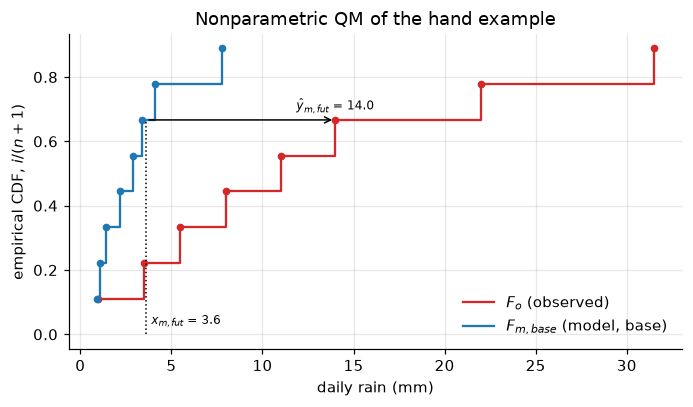

In [6]:
# Section 4.4.2, Part B of the hand example: nonparametric QM on the wet values
print("y_(i):", np.sort(y_o_wet))
print("x_(i):", np.sort(x_b_wet))
print("F = i/(n+1):", np.round(np.arange(1, n1 + 1) / (n1 + 1), 3))
y_hat_m_fut_np = qm_empirical(x_m_fut, x_b_wet, y_o_wet)
print("y_hat_m_fut (the hand answer):", y_hat_m_fut_np)

# Figure 1: the hand example as two staircases, and the path of one future value through Eq. 4.7
F = np.arange(1, n1 + 1) / (n1 + 1)
ys_, xs_ = np.sort(y_o_wet), np.sort(x_b_wet)
fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.step(ys_, F, where="post", color="tab:red", label="$F_o$ (observed)")
ax.step(xs_, F, where="post", color="tab:blue", label="$F_{m,base}$ (model, base)")
ax.plot(ys_, F, "o", color="tab:red", ms=4); ax.plot(xs_, F, "o", color="tab:blue", ms=4)
x0 = 3.6; k = nearest_index(xs_, x0); y0 = qm_empirical(x0, x_b_wet, y_o_wet)[0]
ax.annotate("", xy=(y0, F[k]), xytext=(x0, F[k]), arrowprops=dict(arrowstyle="->", color="k"))
ax.plot([x0, x0], [0, F[k]], "k:", lw=1)
ax.text(x0 + 0.3, 0.02, "$x_{m,fut}$ = 3.6", ha="left", va="bottom", fontsize=8)
ax.text(y0, F[k] + 0.03, "$\\hat y_{m,fut}$ = %.1f" % y0, ha="center", fontsize=8)
ax.set_xlabel("daily rain (mm)"); ax.set_ylabel("empirical CDF, $i/(n+1)$"); ax.legend(frameon=False, loc="lower right")
ax.set_title("Nonparametric QM of the hand example")
plt.tight_layout(); plt.show()

### 4.4.3 Quantile delta mapping

It is critical to keep the relative change that the model projects. Quantile delta mapping (QDM, Cannon et al. 2015) does so. **Plain idea: keep the change the model projects, but fix the starting distribution.** If the model says the heavy rain gets 30 % heavier, the corrected series should also show 30 % heavier heavy rain. The book builds it as follows (Eqs. 4.9 to 4.13).

The probability of the future model value in the ECDF of the future series (its heaviness among future days):

$$\tau_{m,fut} = F_{m,fut}(x_{m,fut}). \tag{4.9}$$

The relative change in quantiles between base and future at that probability (model future value divided by base value of the same probability):

$$\Delta_{m,fut} = \frac{F_{m,fut}^{-1}(\tau_{m,fut})}{F_{m,base}^{-1}(\tau_{m,fut})} = \frac{x_{m,fut}}{F_{m,base}^{-1}(\tau_{m,fut})}. \tag{4.10}$$

The gauge value at that probability, from the inverse ECDF of the observations:

$$\hat y_{o,fut} = F_o^{-1}(\tau_{m,fut}). \tag{4.11}$$

The corrected value applies the model's change to it:

$$\hat y_{m,fut} = \hat y_{o,fut}\,\Delta_{m,fut}, \tag{4.12}$$

or written out in one expression,

$$\hat y_{m,fut} = F_o^{-1}\!\left[F_{m,fut}(x_{m,fut})\right]\,\frac{x_{m,fut}}{F_{m,base}^{-1}\!\left[F_{m,fut}(x_{m,fut})\right]}. \tag{4.13}$$

The book's Example 4.5 uses ECDFs for all three CDFs: sort the future values, get $\tau_{m,fut}$ as $i/(N+1)$, find the base value and the gauge value of that probability by the nearest-ECDF rule, form $\Delta_{m,fut}$, then multiply. Instead of the ratio, an additive change can be used,

$$\Delta_{m,fut} = x_{m,fut} - F_{m,base}^{-1}(\tau_{m,fut}), \tag{4.14}$$
$$\hat y_{m,fut} = \hat y_{o,fut} + \Delta_{m,fut}. \tag{4.15}$$

The code below does these steps for the eight future values; Figure 3 (in 4.5) shows that QDM follows the model's own change at every level.

*What this means for hydrology:* QDM keeps the model's signal of heavier storms, which matters when we ask how much flood risk will change.

In [7]:
# Section 4.4.3: QDM on the eight values (Eqs. 4.9 to 4.15), then all methods side by side
y_hat_qdm, tau_m_fut, Delta_m_fut, y_hat_o_fut = qdm(x_m_fut, x_b_wet, y_o_wet)
y_hat_qdm_add = qdm(x_m_fut, x_b_wet, y_o_wet, additive=True)[0]
table = pd.DataFrame({"x_m_fut": x_m_fut, "tau_m_fut": tau_m_fut, "Delta_m_fut": Delta_m_fut, "y_hat_o_fut": y_hat_o_fut,
                      "delta (4.2)": y_hat_delta, "QM exp": y_hat_exp, "QM gamma": y_hat_gam, "QM empirical": y_hat_m_fut_np, "QDM (4.12)": y_hat_qdm})
print("mean of the eight values: " + ", ".join(f"{c} {table[c].mean():.2f}" for c in ["x_m_fut"] + list(table.columns[4:])))
print("additive QDM (Eq. 4.15):", np.round(y_hat_qdm_add, 3))
table.round(3)

mean of the eight values: x_m_fut 3.80, delta (4.2) 15.41, QM exp 15.41, QM gamma 15.84, QM empirical 14.94, QDM (4.12) 15.78
additive QDM (Eq. 4.15): [ 6.  24.1  0.8 11.7  8.3 33.1  3.6 15.5]


,x_m_fut,tau_m_fut,Delta_m_fut,y_hat_o_fut,delta (4.2),QM exp,QM gamma,QM empirical,QDM (4.12)
0,1.9,0.333,1.357,5.5,6.769,7.704,7.021,8.0,7.464
1,6.2,0.778,1.512,22.0,26.320,25.139,26.675,31.5,33.268
2,0.7,0.111,0.778,1.0,1.312,2.838,2.165,1.0,0.778
3,3.6,0.556,1.241,11.0,14.498,14.597,14.563,14.0,13.655
4,2.5,0.444,1.136,8.0,9.497,10.137,9.627,8.0,9.091
5,9.4,0.889,1.205,31.5,40.870,38.113,42.013,31.5,37.962
6,1.2,0.222,1.091,3.5,3.586,4.866,4.107,3.5,3.818
7,4.9,0.667,1.441,14.0,20.409,19.868,20.561,22.0,20.176


## 4.5 Summary and comparison

- **Occurrence adjustment**: set the lightest model days to zero until the number of wet days matches the gauge.
- **Delta method**: stretch and shift the model's future series to the gauge's mean and spread (Eqs. 4.2 to 4.5). Simple, but it can give negative rain.
- **Quantile mapping** (Eq. 4.7): replace a model value by the gauge value of the same probability, with an exponential, gamma or empirical CDF. The empirical version needs no curve but stops at the largest gauge value.
- **Quantile delta mapping** (Eq. 4.13): the gauge value of that probability times the model's own future-to-base ratio, so the projected change survives.
- Which method is best depends on the use, and is rather subjective: a design flood needs reliable extremes, a drought study the small and medium values. The corrected series should be tested against the aim of the study. The table above puts the eight corrected values side by side; the cell below compares the methods on a larger synthetic sample, as the book's Figure 4.2 does for its data. In Figure 3 the QDM line lies on the model's own change, QM exaggerates it, and the delta method follows it only roughly (and gives negative rain on many days).

```{admonition} The idea to remember
Bias correction moves the model's values to where the gauge says they should be. Whether the model's projected change is believable is a separate question that no correction answers.
```

negative values from the delta method (Eq. 4.2): 115 of 600


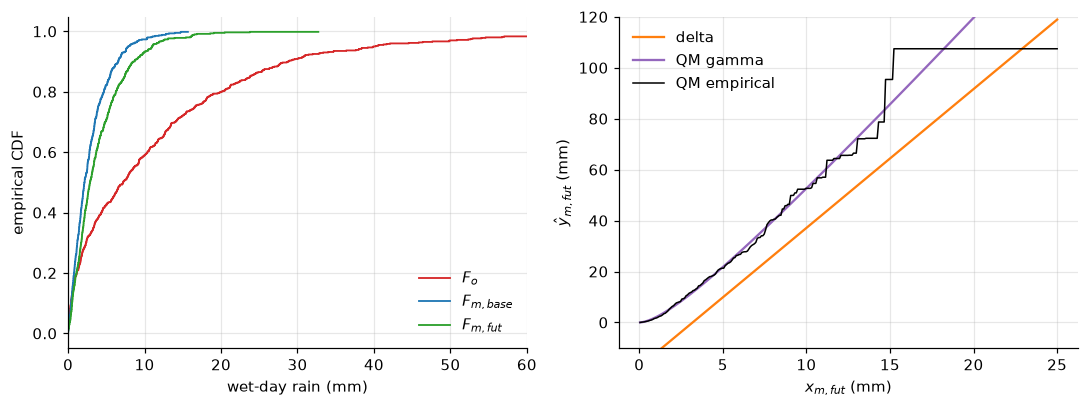

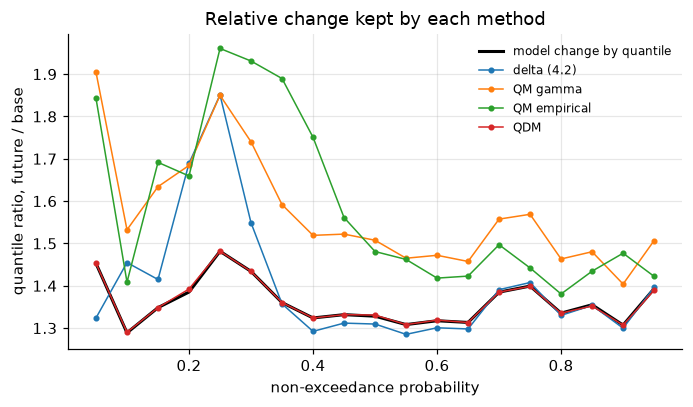

In [8]:
# Section 4.5: a larger synthetic wet-day sample, to see the methods on a realistic number of values (not in the workbook); Figures 2 and 3
rng = np.random.default_rng(18)
Y_obs = rng.gamma(0.6, 20.0, 600)        # observed wet-day rain, mean 12 mm
X_base = rng.gamma(1.2, 2.5, 600)        # model base, mean 3 mm: too light
X_fut = rng.gamma(1.2, 3.4, 600)         # model future: 36 % wetter than the model base


def qm_gamma(x, x_base, y):
    b_o, b_m = y.var(ddof=1) / y.mean(), x_base.var(ddof=1) / x_base.mean()
    return stats.gamma.ppf(stats.gamma.cdf(x, x_base.mean() / b_m, scale=b_m), y.mean() / b_o, scale=b_o)


def qm_np_fast(x, x_base, y):
    xs, ys = np.sort(x_base), np.sort(y)
    j = np.clip(np.searchsorted(xs, x), 1, len(xs) - 1)
    i = np.where(np.abs(x - xs[j - 1]) <= np.abs(xs[j] - x), j - 1, j)
    return ys[np.clip(np.round((i + 1) / (len(xs) + 1) * (len(ys) + 1)).astype(int), 1, len(ys)) - 1]


methods = {"delta (4.2)": lambda x: delta_method(x, X_base, Y_obs)[0], "QM gamma": lambda x: qm_gamma(x, X_base, Y_obs),
           "QM empirical": lambda x: qm_np_fast(x, X_base, Y_obs), "QDM": lambda x: qdm(x, X_base, Y_obs)[0]}
print("negative values from the delta method (Eq. 4.2):", int((methods["delta (4.2)"](X_fut) < 0).sum()), "of", len(X_fut))

# Figure 2: empirical CDFs, and the mapping x_m_fut -> y_hat_m_fut
q = np.arange(1, 601) / 601
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for s, lab, c in ((Y_obs, "$F_o$", "tab:red"), (X_base, "$F_{m,base}$", "tab:blue"), (X_fut, "$F_{m,fut}$", "tab:green")):
    ax[0].step(np.sort(s), q, color=c, label=lab, lw=1.2)
ax[0].set_xlim(0, 60); ax[0].set_xlabel("wet-day rain (mm)"); ax[0].set_ylabel("empirical CDF"); ax[0].legend(frameon=False, loc="lower right")
xx = np.linspace(0.05, 25, 300)
ax[1].plot(xx, methods["delta (4.2)"](xx), color="tab:orange", label="delta")
ax[1].plot(xx, methods["QM gamma"](xx), color="tab:purple", label="QM gamma")
ax[1].plot(xx, methods["QM empirical"](xx), color="k", lw=1, label="QM empirical")
ax[1].set_xlabel("$x_{m,fut}$ (mm)"); ax[1].set_ylabel("$\\hat y_{m,fut}$ (mm)"); ax[1].legend(frameon=False); ax[1].set_ylim(-10, 120)
plt.tight_layout(); plt.show()


# Figure 3: is the model's projected change kept? Ratio of quantiles, corrected future over corrected base
qs = np.linspace(0.05, 0.95, 19)
fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.plot(qs, np.quantile(X_fut, qs) / np.quantile(X_base, qs), "k-", lw=2, label="model change by quantile")
for name, g in methods.items():
    ax.plot(qs, np.quantile(g(X_fut), qs) / np.quantile(g(X_base), qs), "o-", ms=3, lw=1, label=name)
ax.set_xlabel("non-exceedance probability"); ax.set_ylabel("quantile ratio, future / base"); ax.legend(frameon=False, fontsize=8)
ax.set_title("Relative change kept by each method"); plt.tight_layout(); plt.show()

## Check your understanding

1. A model rains on 85 % of days and the gauge on 45 %. Why must the occurrence adjustment come before quantile mapping, and which percentile of the model values is the wet-day threshold for $N = 40$ days and $n_1 = 18$ wet days?
2. In the hand example the future values 1.9 and 2.5 both become 8.0 mm. Why, and which method in the table avoids this staircase?
3. If the model's future series were identical to its base series, what would $\Delta_{m,fut}$ be, and what would the QDM result be equal to?

## Try it yourself

- Add a ninth wet day to $y_{obs}$ and a ninth value to $x_{m,base}$ and repeat the hand example: which corrected values change?
- Replace the ratio $\Delta_{m,fut}$ by the difference (Eq. 4.14) on the larger sample and plot Figure 3 again.
- In the workbook, change one value of $x_{m,fut}$ in `Data` and follow it through `Occ_QM`, `Delta` and `QDM`.

```{note} Where this lecture differs from the book
- Eq. 4.1: the book's worked line shows the variance (42.025) under the fraction; the table uses the standard deviation (6.483), and so does the lecture.
- Eqs. 4.3 and 4.4: the printed ratios were garbled; they are read as $\hat\sigma_{m,fut} = (\sigma_{obs}/\sigma_{m,base})\,\sigma_{m,fut}$ and $\hat\mu_{m,fut} = (\mu_{obs}/\mu_{m,base})\,\mu_{m,fut}$, which Example 4.2 confirms numerically.
- QDM (Eqs. 4.9 to 4.15) was garbled in the extraction; the lecture reconstructs it from Example 4.5 and its captions as $\tau_{m,fut} = F_{m,fut}(x_{m,fut})$, $\Delta_{m,fut} = x_{m,fut}/F_{m,base}^{-1}(\tau_{m,fut})$, $\hat y_{o,fut} = F_o^{-1}(\tau_{m,fut})$ and $\hat y_{m,fut} = \hat y_{o,fut}\Delta_{m,fut}$; the additive form is Eqs. 4.14 and 4.15.
- Section 4.2 gives the threshold as 2.44 mm and as 2.4 mm; the lecture uses the $n_1$th largest model value itself.
- The empirical mapping uses the book's nearest-value rule; interpolation between values is a common refinement that is not used.
```

```{note} Sources
Written for **CE524 Applied Hydroclimatology**. The reference is Lee, T., & Singh, V. P. (2019). *Statistical Downscaling for Hydrological and Environmental Applications*. CRC Press, Chapter 4 (occurrence adjustment, Section 4.2; empirical adjustment, 4.3; quantile mapping, 4.4; summary and comparison, 4.5). Quantile delta mapping: Cannon, A. J., Sobie, S. R., & Murdock, T. Q. (2015). *J. Climate, 28*, 6938&ndash;6959. The explanations, synthetic data, worked example, workbook and figures were made for this course and do not reproduce the book's tables or examples. Related lectures: 14 (delta change), 16, 17, 19 to 23.

Text under CC BY-SA 4.0, code additionally under the MIT License; full attribution in [CREDITS.md](https://github.com/drvivekhydro/hydroclimatology/blob/main/CREDITS.md).
```